<a href="https://colab.research.google.com/github/asl0180/-my-first-website/blob/main/UntitBrowser_Artefact_clusteringled6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

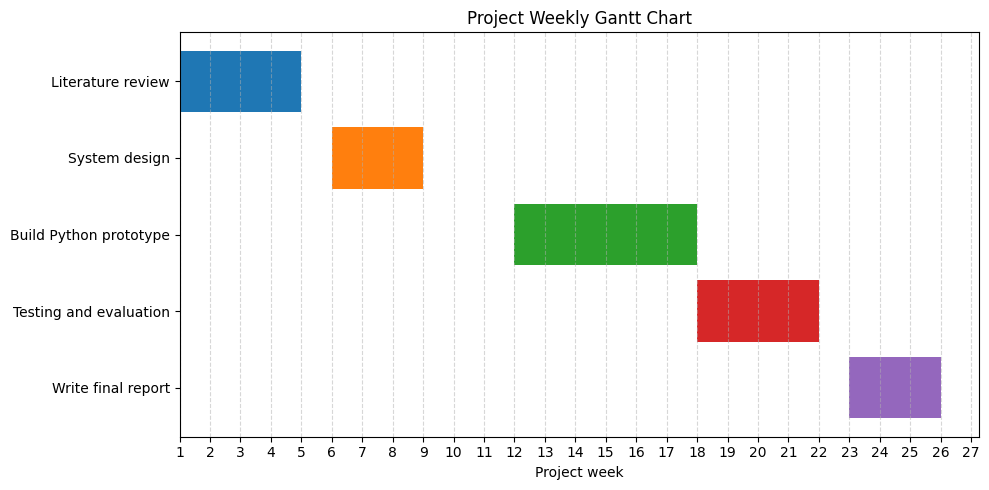

In [1]:
import matplotlib.pyplot as plt

# Task name, starting week, duration
tasks = [
    ("Literature review", 1, 4),
    ("System design", 6, 3),
    ("Build Python prototype", 12, 6),
    ("Testing and evaluation", 18, 4),
    ("Write final report", 23, 3),
]

fig, ax = plt.subplots(figsize=(10, 5))

for y, (task, start, duration) in enumerate(tasks):
    ax.barh(y, duration, left=start)

ax.set_yticks(range(len(tasks)))
ax.set_yticklabels([task for task, _, _ in tasks])
ax.invert_yaxis()
ax.set_xlabel("Project week")
ax.set_title("Project Weekly Gantt Chart")
ax.set_xticks(range(1, 28))
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [2]:
import pandas as pd

# Load the uploaded CSV file
df = pd.read_csv('/content/synthetic-browsing-history-PT_1.csv')

# Display the first five records
print("First five records:")
display(df.head())

# Display dataset dimensions
print("Dataset dimensions:", df.shape)

# Display column names and data types
print("\nColumn information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

First five records:


,synthetic_time,synthetic_url,original_scope,original_content,original_country_rank,original_world_rank,original_path_bin
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,Global,Society,-1,100000,50
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,Global,News,-1,10000,-1
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,Global,News,-1,10000,-1
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,Global,News,-1,10000,25
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,Global,Business,-1,10000,50


Dataset dimensions: (2123, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2123 entries, 0 to 2122
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   synthetic_time         2123 non-null   object
 1   synthetic_url          2123 non-null   object
 2   original_scope         2123 non-null   object
 3   original_content       2123 non-null   object
 4   original_country_rank  2123 non-null   int64 
 5   original_world_rank    2123 non-null   int64 
 6   original_path_bin      2123 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 116.2+ KB

Missing values:
synthetic_time           0
synthetic_url            0
original_scope           0
original_content         0
original_country_rank    0
original_world_rank      0
original_path_bin        0
dtype: int64

Duplicate records: 0


In [3]:
import pandas as pd
from urllib.parse import urlparse

# Create a separate working copy
df_clean = df.copy()

# Convert timestamps into proper datetime values
df_clean["synthetic_time"] = pd.to_datetime(
    df_clean["synthetic_time"],
    errors="coerce"
)

# Standardise URL text to lowercase
df_clean["synthetic_url"] = (
    df_clean["synthetic_url"].astype(str).str.strip().str.lower()
)

# Extract the domain from each URL
df_clean["domain"] = df_clean["synthetic_url"].apply(
    lambda url: urlparse(url).netloc
)

# Create a flag for unavailable numerical values
# Keep the original -1 values unchanged
for col in [
    "original_country_rank",
    "original_world_rank",
    "original_path_bin"
]:
    df_clean[col + "_unavailable"] = df_clean[col] == -1

# Display the cleaned data
display(df_clean.head(10))

# Check the results
print("Working copy dimensions:", df_clean.shape)
print("Invalid timestamps:", df_clean["synthetic_time"].isna().sum())
print("Empty URLs:", (df_clean["synthetic_url"] == "").sum())
print("Empty domains:", (df_clean["domain"] == "").sum())

# Confirm the original DataFrame is unchanged
print("Original dimensions:", df.shape)

,synthetic_time,synthetic_url,original_scope,original_content,original_country_rank,original_world_rank,original_path_bin,domain,original_country_rank_unavailable,original_world_rank_unavailable,original_path_bin_unavailable
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,Global,Society,-1,100000,50,www.cm-abrantes.pt,True,False,False
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,Global,News,-1,10000,-1,kitesurf-algarve.com,True,False,True
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,Global,News,-1,10000,-1,kitesurf-algarve.com,True,False,True
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,Global,News,-1,10000,25,kitesurf-algarve.com,True,False,False
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,Global,Business,-1,10000,50,hotelmestredeavis.pt,True,False,False
5,2024-11-01 09:30:23.517065,https://www.cm-cantanhede.pt/mcsite/documentos...,Global,Society,-1,100000,50,www.cm-cantanhede.pt,True,False,False
6,2024-11-01 09:30:24.947278,https://www.jf-canico.pt/autarquia/noticias/10...,Global,Society,-1,100000,50,www.jf-canico.pt,True,False,False
7,2024-11-01 10:20:28.748353,https://notarios.pt/notarios/130-282-ana-rita-sa,Global,Society,-1,100000,50,notarios.pt,True,False,False
8,2024-11-01 10:20:35.959636,https://amadeosouza-cardoso.pt/pt/product/jarr...,Global,Society,-1,100000,50,amadeosouza-cardoso.pt,True,False,False
9,2024-11-01 10:30:36.776618,https://kitesurf-algarve.com/kitesurf-in-lagos...,Global,News,-1,10000,-1,kitesurf-algarve.com,True,False,True


Working copy dimensions: (2123, 11)
Invalid timestamps: 0
Empty URLs: 0
Empty domains: 0
Original dimensions: (2123, 7)


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a text column using the URL
df_clean["url_text"] = (
    df_clean["synthetic_url"]
    .str.replace(r"https?://", " ", regex=True)
    .str.replace(r"www\.", " ", regex=True)
    .str.replace(r"[^a-zA-Z0-9]", " ", regex=True)
)

# Convert URL text into TF-IDF numerical features
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=500
)

tfidf_matrix = vectorizer.fit_transform(df_clean["url_text"])

# Display results
print("TF-IDF matrix shape:", tfidf_matrix.shape)

print("\nFirst 20 extracted features:")
print(vectorizer.get_feature_names_out()[:20])

print("\nFirst 5 URL records:")
display(df_clean[["synthetic_url", "url_text"]].head())

TF-IDF matrix shape: (2123, 500)

First 20 extracted features:
['01' '02' '03' '04' '05' '06' '08' '09' '10' '1001' '109' '11' '11310'
 '12' '12688009' '12883855' '12899537' '13' '134' '137']

First 5 URL records:


,synthetic_url,url_text
0,http://www.cm-abrantes.pt/index.php/os-nossos-...,cm abrantes pt index php os nossos incentivos
1,https://kitesurf-algarve.com/top-5-mistakes-ne...,kitesurf algarve com top 5 mistakes new kites...
2,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf algarve com kitesurf in lagos portug...
3,https://kitesurf-algarve.com/page/3/,kitesurf algarve com page 3
4,https://hotelmestredeavis.pt/en/?nuss_footer=f...,hotelmestredeavis pt en nuss footer footer 01 2


In [5]:
# Display the 50 most common extracted terms
feature_names = vectorizer.get_feature_names_out()

print("First 50 extracted features:")
print(feature_names[:50])

# Display some complete URL examples and cleaned text
for i in range(10):
    print("\nOriginal URL:", df_clean["synthetic_url"].iloc[i])
    print("Extracted text:", df_clean["url_text"].iloc[i])

First 50 extracted features:
['01' '02' '03' '04' '05' '06' '08' '09' '10' '1001' '109' '11' '11310'
 '12' '12688009' '12883855' '12899537' '13' '134' '137' '150000282608383'
 '150001104721453' '1665874547661' '1671056833624' '16820' '17' '18' '18k'
 '19' '20' '2008' '2011' '2012' '2013' '2014' '2016' '2019' '2020' '2021'
 '2023' '2024' '2025' '23' '23017' '240904' '2580' '275403' '32342'
 '32446' '32464']

Original URL: http://www.cm-abrantes.pt/index.php/os-nossos-incentivos
Extracted text:   cm abrantes pt index php os nossos incentivos

Original URL: https://kitesurf-algarve.com/top-5-mistakes-new-kitesurfers-make-at-schools-in-lagos/
Extracted text:  kitesurf algarve com top 5 mistakes new kitesurfers make at schools in lagos 

Original URL: https://kitesurf-algarve.com/kitesurf-in-lagos-portugal-the-ultimate-guide-to-an-unforgettable-adventure/
Extracted text:  kitesurf algarve com kitesurf in lagos portugal the ultimate guide to an unforgettable adventure 

Original URL: https:/

In [6]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# Common URL components to exclude in this experiment
custom_stop_words = ["www", "com", "pt"]

def clean_url_text(text):
    # Keep tokens that contain letters and are at least 3 characters long
    tokens = re.findall(r"[a-zA-Z][a-zA-Z0-9]{2,}", text)

    # Remove common URL components
    tokens = [
        token for token in tokens
        if token.lower() not in custom_stop_words
    ]

    return " ".join(tokens)

# Create improved text features
df_clean["url_text_v2"] = df_clean["synthetic_url"].apply(
    clean_url_text
)

# Generate a new TF-IDF matrix
vectorizer_v2 = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=500
)

tfidf_matrix_v2 = vectorizer_v2.fit_transform(
    df_clean["url_text_v2"]
)

# Display results
print("Improved TF-IDF matrix shape:", tfidf_matrix_v2.shape)

print("\nFirst 30 extracted features:")
print(vectorizer_v2.get_feature_names_out()[:30])

print("\nExample cleaned URLs:")
display(df_clean[[
    "synthetic_url",
    "url_text_v2"
]].head(10))

Improved TF-IDF matrix shape: (2123, 500)

First 30 extracted features:
['abrantes' 'abril' 'acao' 'acessorios' 'acoes' 'administrativo'
 'adventure' 'afazendarecord' 'agenda' 'aigra' 'ajuda' 'alertar' 'algarve'
 'almada' 'alteracao' 'amadeosouza' 'ame' 'amorim' 'ana' 'anaplan'
 'android' 'apitadadopai' 'apoio' 'app' 'aria2' 'armv7l' 'arnes'
 'arquivos' 'artesanato' 'artigos']

Example cleaned URLs:


,synthetic_url,url_text_v2
0,http://www.cm-abrantes.pt/index.php/os-nossos-...,http abrantes index php nossos incentivos
1,https://kitesurf-algarve.com/top-5-mistakes-ne...,https kitesurf algarve top mistakes new kitesu...
2,https://kitesurf-algarve.com/kitesurf-in-lagos...,https kitesurf algarve kitesurf lagos portugal...
3,https://kitesurf-algarve.com/page/3/,https kitesurf algarve page
4,https://hotelmestredeavis.pt/en/?nuss_footer=f...,https hotelmestredeavis nuss footer footer
5,https://www.cm-cantanhede.pt/mcsite/documentos...,https cantanhede mcsite documentos municipio
6,https://www.jf-canico.pt/autarquia/noticias/10...,https canico autarquia noticias fontenario sec...
7,https://notarios.pt/notarios/130-282-ana-rita-sa,https notarios notarios ana rita
8,https://amadeosouza-cardoso.pt/pt/product/jarr...,https amadeosouza cardoso product jarra corpus...
9,https://kitesurf-algarve.com/kitesurf-in-lagos...,https kitesurf algarve kitesurf lagos portugal...


In [7]:
# Update URL text cleaning
def clean_url_text(text):
    tokens = re.findall(r"[a-zA-Z][a-zA-Z0-9]{2,}", text)

    custom_stop_words = [
        "www", "com", "pt", "http", "https"
    ]

    tokens = [
        token for token in tokens
        if token.lower() not in custom_stop_words
    ]

    return " ".join(tokens)

# Recreate cleaned URL text
df_clean["url_text_v2"] = df_clean["synthetic_url"].apply(
    clean_url_text
)

# Rebuild TF-IDF matrix
vectorizer_v2 = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=500
)

tfidf_matrix_v2 = vectorizer_v2.fit_transform(
    df_clean["url_text_v2"]
)

print("TF-IDF matrix shape:", tfidf_matrix_v2.shape)

print("\nFirst 30 features:")
print(vectorizer_v2.get_feature_names_out()[:30])

TF-IDF matrix shape: (2123, 500)

First 30 features:
['abrantes' 'abril' 'acao' 'acessorios' 'acoes' 'administrativo'
 'adventure' 'afazendarecord' 'agenda' 'aigra' 'air' 'ajuda' 'alertar'
 'algarve' 'almada' 'alteracao' 'amadeosouza' 'ame' 'amorim' 'ana'
 'anaplan' 'android' 'apitadadopai' 'apoio' 'app' 'aria2' 'armv7l' 'arnes'
 'arquivos' 'artesanato']


In [8]:
print("Number of records:", tfidf_matrix_v2.shape[0])
print("Number of features:", tfidf_matrix_v2.shape[1])
print("Non-zero values:", tfidf_matrix_v2.nnz)

print(
    "Matrix density:",
    round(
        tfidf_matrix_v2.nnz /
        (tfidf_matrix_v2.shape[0] * tfidf_matrix_v2.shape[1]),
        4
    )
)

Number of records: 2123
Number of features: 500
Non-zero values: 10646
Matrix density: 0.01


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
cluster_options = [3, 4, 5, 6]

results = []

for k in cluster_options:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(tfidf_matrix_v2)

    score = silhouette_score(
        tfidf_matrix_v2,
        labels,
        metric="cosine"
    )

    results.append({
        "Number of clusters": k,
        "Silhouette score": round(score, 4)
    })

# Display comparison
results_df = pd.DataFrame(results)
display(results_df)

,Number of clusters,Silhouette score
0,3,0.1640
1,4,0.1726
2,5,0.1850
3,6,0.2164


In [10]:
# Train the selected K-means model
kmeans_model = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Assign each browsing record to a cluster
df_clustered = df_clean.copy()
df_clustered["kmeans_cluster"] = kmeans_model.fit_predict(
    tfidf_matrix_v2
)

# Show the number of records in each cluster
print("K-means cluster sizes:")
display(
    df_clustered["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of records")
)

# Display an interactive table in Google Colab
display(
    df_clustered[[
        "synthetic_time",
        "synthetic_url",
        "domain",
        "original_content",
        "kmeans_cluster"
    ]].sort_values("kmeans_cluster")
)

K-means cluster sizes:


,Cluster,Number of records
0,0,872
1,1,136
2,2,220
3,3,351
4,4,393
5,5,151


,synthetic_time,synthetic_url,domain,original_content,kmeans_cluster
649,2024-11-12 13:13:05.449982,https://amadeosouza-cardoso.pt/pt/artistas/lea...,amadeosouza-cardoso.pt,Society,0
686,2024-11-12 20:36:13.348320,https://espinho.pt/pt/viver/municipes/urbanismo/,espinho.pt,Society,0
687,2024-11-12 20:36:14.638881,https://www.occ.pt/pt-pt/homepage,www.occ.pt,Society,0
656,2024-11-12 13:47:12.467910,https://cm-vpaguiar.pt/calamidade-dos-incendio...,cm-vpaguiar.pt,Society,0
665,2024-11-12 15:28:15.312148,https://www.marialva.pt/freguesia/empresas/5-q...,www.marialva.pt,Society,0
...,...,...,...,...,...
1161,2024-11-18 11:11:59.081621,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News,5
2078,2024-11-30 11:09:54.163264,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News,5
1240,2024-11-19 10:40:42.946055,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News,5
29,2024-11-01 14:11:08.405359,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News,5


In [11]:
# Inspect 10 URLs from each cluster
for cluster in sorted(df_clustered["kmeans_cluster"].unique()):

    print(f"\n========== CLUSTER {cluster} ==========")

    sample = df_clustered[
        df_clustered["kmeans_cluster"] == cluster
    ]

    display(
        sample[[
            "synthetic_url",
            "original_content",
            "domain"
        ]].head(10)
    )


========== CLUSTER 0 ==========


,synthetic_url,original_content,domain
0,http://www.cm-abrantes.pt/index.php/os-nossos-...,Society,www.cm-abrantes.pt
4,https://hotelmestredeavis.pt/en/?nuss_footer=f...,Business,hotelmestredeavis.pt
6,https://www.jf-canico.pt/autarquia/noticias/10...,Society,www.jf-canico.pt
7,https://notarios.pt/notarios/130-282-ana-rita-sa,Society,notarios.pt
8,https://amadeosouza-cardoso.pt/pt/product/jarr...,Society,amadeosouza-cardoso.pt
18,https://www.kwai.com/@lais.cintra?fid=15000110...,Shopping,www.kwai.com
26,https://www.marialva.pt/autarquia/boletins-inf...,Society,www.marialva.pt
27,https://www.verklaro.tv/no&ca/2011/02/catering...,Society,www.verklaro.tv
33,http://amadeosouza-cardoso.pt/pt/product/aauca...,Society,amadeosouza-cardoso.pt
34,https://www.galoresort.com/,Business,www.galoresort.com



========== CLUSTER 1 ==========


,synthetic_url,original_content,domain
14,https://stswww.blogspot.com/2016/05/at-anaplan...,Society,stswww.blogspot.com
24,https://stswww.blogspot.com/2012/04/green-inno...,Society,stswww.blogspot.com
25,https://stswww.blogspot.com/2011/02/,Society,stswww.blogspot.com
36,https://stswww.blogspot.com/2014/10/telco-deal...,Society,stswww.blogspot.com
100,https://stswww.blogspot.com/2012/03/vision-of-...,Society,stswww.blogspot.com
102,https://stswww.blogspot.com/2008/01/,Society,stswww.blogspot.com
107,https://stswww.blogspot.com/2012/09/,Society,stswww.blogspot.com
128,https://stswww.blogspot.com/2014/10/telco-deal...,Society,stswww.blogspot.com
129,https://stswww.blogspot.com/2012/03/vision-of-...,Society,stswww.blogspot.com
131,https://stswww.blogspot.com/2014/10/telco-deal...,Society,stswww.blogspot.com



========== CLUSTER 2 ==========


,synthetic_url,original_content,domain
5,https://www.cm-cantanhede.pt/mcsite/documentos...,Society,www.cm-cantanhede.pt
15,https://cm-cantanhede.pt/mcsite/documento/1131...,Society,cm-cantanhede.pt
16,https://www.cm-cantanhede.pt/mcsite/noticia/32...,Society,www.cm-cantanhede.pt
17,https://www.cm-cantanhede.pt/mcsite/pagina/507...,Society,www.cm-cantanhede.pt
19,https://www.cm-cantanhede.pt/mcsite/noticia/16...,Society,www.cm-cantanhede.pt
20,https://www.cm-cantanhede.pt/search.asp?/imita...,Society,www.cm-cantanhede.pt
21,https://www.cm-cantanhede.pt/mcsite/noticia/16...,Society,www.cm-cantanhede.pt
22,https://www.cm-cantanhede.pt/search.asp?/imita...,Society,www.cm-cantanhede.pt
23,https://www.cm-cantanhede.pt/mcsite/documento/...,Society,www.cm-cantanhede.pt
56,https://www.cm-cantanhede.pt/mcsite/pagina/507...,Society,www.cm-cantanhede.pt


... (2 outputs left out)


========== CLUSTER 4 ==========


,synthetic_url,original_content,domain
13,https://iefp.pt,Business,iefp.pt
54,https://iefp.pt,Business,iefp.pt
55,https://www.iefp.pt/en_gb/estatisticas,Business,www.iefp.pt
60,https://iefp.pt,Business,iefp.pt
63,https://iefp.pt,Business,iefp.pt
64,https://www.iefp.pt/en_gb/estatisticas,Business,www.iefp.pt
65,https://www.iefp.pt/en_gb/portugal2030-regras-...,Business,www.iefp.pt
66,https://www.iefp.pt/en_gb/noticias,Business,www.iefp.pt
67,https://www.iefp.pt/en_gb/estatisticas,Business,www.iefp.pt
68,https://iefp.pt/noticias?item=4514049,Business,iefp.pt



========== CLUSTER 5 ==========


,synthetic_url,original_content,domain
10,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com
29,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com
30,https://kitesurf-algarve.com/riding-kiteboard-...,News,kitesurf-algarve.com
42,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com
43,https://kitesurf-algarve.com/riding-kiteboard-...,News,kitesurf-algarve.com
104,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com
136,https://kitesurf-algarve.com/riding-kiteboard-...,News,kitesurf-algarve.com
167,https://kitesurf-algarve.com/riding-kiteboard-...,News,kitesurf-algarve.com
181,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com
192,https://kitesurf-algarve.com/find-your-perfect...,News,kitesurf-algarve.com


,Cluster,Number of records,Percentage
0,0,872,41.07
1,1,136,6.41
2,2,220,10.36
3,3,351,16.53
4,4,393,18.51
5,5,151,7.11


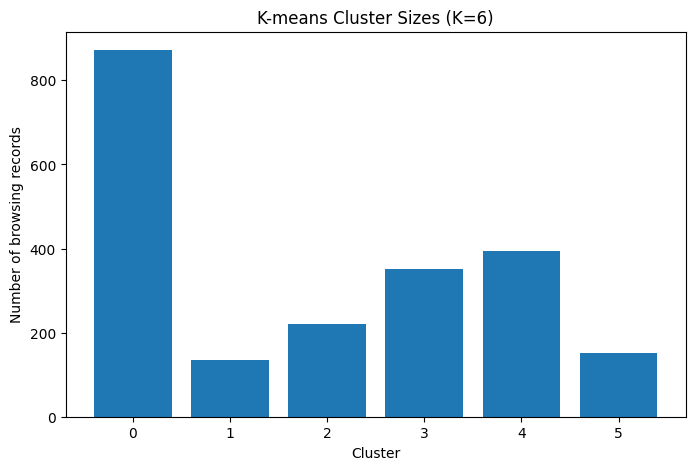

In [12]:
# Calculate the size of each K-means cluster
cluster_sizes = (
    df_clustered["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_sizes.columns = [
    "Cluster",
    "Number of records"
]

# Calculate percentage of the dataset
cluster_sizes["Percentage"] = (
    cluster_sizes["Number of records"] /
    len(df_clustered) * 100
).round(2)

display(cluster_sizes)

# Visualise cluster sizes
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    cluster_sizes["Cluster"].astype(str),
    cluster_sizes["Number of records"]
)

plt.title("K-means Cluster Sizes (K=6)")
plt.xlabel("Cluster")
plt.ylabel("Number of browsing records")
plt.show()

In [13]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

# Test different eps values
eps_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
min_samples = 5

dbscan_results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="cosine",
        algorithm="brute"
    )

    labels = model.fit_predict(tfidf_matrix_v2)

    # Count clusters, excluding noise (-1)
    number_of_clusters = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    noise_count = (labels == -1).sum()

    # Calculate silhouette only for non-noise records
    non_noise = labels != -1
    valid_labels = labels[non_noise]

    if (
        len(set(valid_labels)) >= 2
        and len(set(valid_labels)) < len(valid_labels)
    ):
        score = silhouette_score(
            tfidf_matrix_v2[non_noise],
            valid_labels,
            metric="cosine"
        )
    else:
        score = None

    dbscan_results.append({
        "Epsilon": eps,
        "Clusters": number_of_clusters,
        "Noise records": noise_count,
        "Silhouette score": score
    })

dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df)

,Epsilon,Clusters,Noise records,Silhouette score
0,0.2,96,479,0.986278
1,0.3,101,397,0.958529
2,0.4,106,276,0.903083
3,0.5,89,142,0.680700
4,0.6,37,63,0.300850
5,0.7,16,33,0.105894


In [14]:
from sklearn.cluster import DBSCAN

# Run DBSCAN with eps = 0.5
dbscan_model = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="cosine",
    algorithm="brute"
)

# Store the results in a separate copy
df_dbscan = df_clean.copy()

df_dbscan["dbscan_cluster"] = dbscan_model.fit_predict(
    tfidf_matrix_v2
)

# Count records in each cluster, including noise
dbscan_cluster_sizes = (
    df_dbscan["dbscan_cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

dbscan_cluster_sizes.columns = [
    "Cluster",
    "Number of records"
]

# Calculate percentages
dbscan_cluster_sizes["Percentage"] = (
    dbscan_cluster_sizes["Number of records"]
    / len(df_dbscan) * 100
).round(2)

display(dbscan_cluster_sizes)

# Count noise records
noise_count = (
    df_dbscan["dbscan_cluster"] == -1
).sum()

print("Noise records:", noise_count)
print(
    "Number of actual clusters:",
    df_dbscan["dbscan_cluster"].nunique()
    - (1 if -1 in df_dbscan["dbscan_cluster"].values else 0)
)

,Cluster,Number of records,Percentage
0,-1,142,6.69
1,0,58,2.73
2,1,74,3.49
3,2,69,3.25
4,3,208,9.80
...,...,...,...
85,84,5,0.24
86,85,8,0.38
87,86,6,0.28
88,87,5,0.24


Noise records: 142
Number of actual clusters: 89


In [15]:
# Inspect up to 10 records from the largest DBSCAN clusters
largest_clusters = (
    df_dbscan[df_dbscan["dbscan_cluster"] != -1]
    ["dbscan_cluster"]
    .value_counts()
    .head(5)
    .index
)

for cluster in largest_clusters:

    print(f"\n========== DBSCAN CLUSTER {cluster} ==========")

    sample = df_dbscan[
        df_dbscan["dbscan_cluster"] == cluster
    ]

    display(
        sample[[
            "synthetic_url",
            "domain",
            "original_content"
        ]].head(10)
    )

# Inspect noise records separately
print("\n========== NOISE RECORDS ==========")

display(
    df_dbscan[
        df_dbscan["dbscan_cluster"] == -1
    ][[
        "synthetic_url",
        "domain",
        "original_content"
    ]].head(10)
)


========== DBSCAN CLUSTER 3 ==========


,synthetic_url,domain,original_content
3,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
11,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
12,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
31,https://kitesurf-algarve.com/page/18/,kitesurf-algarve.com,News
32,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
38,https://kitesurf-algarve.com/page/13/,kitesurf-algarve.com,News
39,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
40,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
44,https://kitesurf-algarve.com/page/18/,kitesurf-algarve.com,News
45,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News



========== DBSCAN CLUSTER 9 ==========


,synthetic_url,domain,original_content
13,https://iefp.pt,iefp.pt,Business
54,https://iefp.pt,iefp.pt,Business
60,https://iefp.pt,iefp.pt,Business
63,https://iefp.pt,iefp.pt,Business
66,https://www.iefp.pt/en_gb/noticias,www.iefp.pt,Business
68,https://iefp.pt/noticias?item=4514049,iefp.pt,Business
69,https://www.iefp.pt/noticias?item=12899537,www.iefp.pt,Business
70,https://www.iefp.pt/en_gb/noticias,www.iefp.pt,Business
111,https://iefp.pt,iefp.pt,Business
117,https://iefp.pt,iefp.pt,Business



========== DBSCAN CLUSTER 20 ==========


,synthetic_url,domain,original_content
25,https://stswww.blogspot.com/2011/02/,stswww.blogspot.com,Society
36,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
102,https://stswww.blogspot.com/2008/01/,stswww.blogspot.com,Society
107,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
128,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
131,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
133,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
147,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
149,https://stswww.blogspot.com/2011/02/,stswww.blogspot.com,Society
154,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society


... (2 outputs left out)


========== DBSCAN CLUSTER 15 ==========


,synthetic_url,domain,original_content
19,https://www.cm-cantanhede.pt/mcsite/noticia/16...,www.cm-cantanhede.pt,Society
21,https://www.cm-cantanhede.pt/mcsite/noticia/16...,www.cm-cantanhede.pt,Society
41,https://www.vendus.pt/ajuda/tipos-de-pagamento/,www.vendus.pt,Society
106,https://www.vendus.pt/ajuda/como-comunicar-as-...,www.vendus.pt,Society
146,https://www.vendus.pt/blog/criar-empresa-nome-...,www.vendus.pt,Society
184,https://www.vendus.pt/blog/tipos-de-empreended...,www.vendus.pt,Society
233,https://www.vendus.pt/blog/gestao-de-fornecedo...,www.vendus.pt,Society
238,https://apadariaportuguesa.pt/produtos/,apadariaportuguesa.pt,Business
246,https://www.vendus.pt/blog/restauracao-cafetar...,www.vendus.pt,Society
308,https://www.aldi.pt/produto/fiambre-da-perna-e...,www.aldi.pt,Shopping



========== NOISE RECORDS ==========


,synthetic_url,domain,original_content
46,https://www.montanheiros.com/2019/06/20/caminh...,www.montanheiros.com,Society
51,https://espinho.pt,espinho.pt,Society
57,https://www.cm-gaia.pt/pt/cidade/protecao-civi...,www.cm-gaia.pt,Society
74,https://www.kwai.com/@desinteligencia_huma,www.kwai.com,Shopping
110,https://cm-vpaguiar.pt/termos-e-condicoes-rede...,cm-vpaguiar.pt,Society
134,https://espinho.pt/pt/galerias/visita-ao-centr...,espinho.pt,Society
135,https://cm-cinfaes.pt/apoio-ao-municipe/toponimia,cm-cinfaes.pt,Society
148,https://www.kwai.com/@foxagency,www.kwai.com,Society
150,https://www.kwai.com/@istudiomds,www.kwai.com,Society
155,https://www.kwai.com/@istudiomds,www.kwai.com,Society


In [16]:
from google.colab import data_table

# Sort clusters by number of records, largest first
dbscan_cluster_sizes = (
    df_dbscan["dbscan_cluster"]
    .value_counts()
    .rename_axis("Cluster")
    .reset_index(name="Number of records")
)

# Calculate percentages
dbscan_cluster_sizes["Percentage"] = (
    dbscan_cluster_sizes["Number of records"]
    / len(df_dbscan) * 100
).round(2)

# Put the noise group (-1) at the top
dbscan_cluster_sizes["Sort_order"] = (
    dbscan_cluster_sizes["Cluster"] != -1
).astype(int)

dbscan_cluster_sizes = (
    dbscan_cluster_sizes
    .sort_values(
        ["Sort_order", "Number of records"],
        ascending=[True, False]
    )
    .drop(columns="Sort_order")
    .reset_index(drop=True)
)

# Display an interactive table
data_table.DataTable(
    dbscan_cluster_sizes,
    include_index=False,
    num_rows_per_page=20
)

,Cluster,Number of records,Percentage
0,-1,142,6.69
1,3,208,9.80
2,9,207,9.75
3,20,93,4.38
4,8,78,3.67
...,...,...,...
85,37,5,0.24
86,50,5,0.24
87,80,5,0.24
88,84,5,0.24


In [17]:
actual_clusters = (
    df_dbscan["dbscan_cluster"].nunique()
    - (1 if -1 in df_dbscan["dbscan_cluster"].values else 0)
)

noise_count = (df_dbscan["dbscan_cluster"] == -1).sum()
clustered_count = len(df_dbscan) - noise_count

print("DBSCAN SUMMARY")
print("-------------------------")
print("Total records:", len(df_dbscan))
print("Actual clusters:", actual_clusters)
print("Records assigned to clusters:", clustered_count)
print("Noise records:", noise_count)
print("Noise percentage:", round(noise_count / len(df_dbscan) * 100, 2), "%")

DBSCAN SUMMARY
-------------------------
Total records: 2123
Actual clusters: 89
Records assigned to clusters: 1981
Noise records: 142
Noise percentage: 6.69 %


In [18]:
# Find the five largest DBSCAN clusters, excluding noise
largest_clusters = (
    df_dbscan[df_dbscan["dbscan_cluster"] != -1]
    ["dbscan_cluster"]
    .value_counts()
    .head(5)
    .index
)

# Display up to 15 records from each cluster
for cluster in largest_clusters:
    print(f"\n========== CLUSTER {cluster} ==========")

    sample = df_dbscan[
        df_dbscan["dbscan_cluster"] == cluster
    ]

    display(
        sample[
            ["synthetic_url", "domain", "original_content"]
        ].head(15)
    )


========== CLUSTER 3 ==========


,synthetic_url,domain,original_content
3,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
11,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
12,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
31,https://kitesurf-algarve.com/page/18/,kitesurf-algarve.com,News
32,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
38,https://kitesurf-algarve.com/page/13/,kitesurf-algarve.com,News
39,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News
40,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,News
44,https://kitesurf-algarve.com/page/18/,kitesurf-algarve.com,News
45,https://kitesurf-algarve.com/kitesurfing-portu...,kitesurf-algarve.com,News



========== CLUSTER 9 ==========


,synthetic_url,domain,original_content
13,https://iefp.pt,iefp.pt,Business
54,https://iefp.pt,iefp.pt,Business
60,https://iefp.pt,iefp.pt,Business
63,https://iefp.pt,iefp.pt,Business
66,https://www.iefp.pt/en_gb/noticias,www.iefp.pt,Business
68,https://iefp.pt/noticias?item=4514049,iefp.pt,Business
69,https://www.iefp.pt/noticias?item=12899537,www.iefp.pt,Business
70,https://www.iefp.pt/en_gb/noticias,www.iefp.pt,Business
111,https://iefp.pt,iefp.pt,Business
117,https://iefp.pt,iefp.pt,Business



========== CLUSTER 20 ==========


,synthetic_url,domain,original_content
25,https://stswww.blogspot.com/2011/02/,stswww.blogspot.com,Society
36,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
102,https://stswww.blogspot.com/2008/01/,stswww.blogspot.com,Society
107,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
128,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
131,https://stswww.blogspot.com/2014/10/telco-deal...,stswww.blogspot.com,Society
133,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
147,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society
149,https://stswww.blogspot.com/2011/02/,stswww.blogspot.com,Society
154,https://stswww.blogspot.com/2012/09/,stswww.blogspot.com,Society



========== CLUSTER 8 ==========


,synthetic_url,domain,original_content
10,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
29,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
42,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
104,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
181,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
192,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
201,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
222,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
272,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News
362,https://kitesurf-algarve.com/find-your-perfect...,kitesurf-algarve.com,News



========== CLUSTER 15 ==========


,synthetic_url,domain,original_content
19,https://www.cm-cantanhede.pt/mcsite/noticia/16...,www.cm-cantanhede.pt,Society
21,https://www.cm-cantanhede.pt/mcsite/noticia/16...,www.cm-cantanhede.pt,Society
41,https://www.vendus.pt/ajuda/tipos-de-pagamento/,www.vendus.pt,Society
106,https://www.vendus.pt/ajuda/como-comunicar-as-...,www.vendus.pt,Society
146,https://www.vendus.pt/blog/criar-empresa-nome-...,www.vendus.pt,Society
184,https://www.vendus.pt/blog/tipos-de-empreended...,www.vendus.pt,Society
233,https://www.vendus.pt/blog/gestao-de-fornecedo...,www.vendus.pt,Society
238,https://apadariaportuguesa.pt/produtos/,apadariaportuguesa.pt,Business
246,https://www.vendus.pt/blog/restauracao-cafetar...,www.vendus.pt,Society
308,https://www.aldi.pt/produto/fiambre-da-perna-e...,www.aldi.pt,Shopping


In [19]:
# TEST 5A: K-means clustering validation

from sklearn.cluster import KMeans

# Recreate the selected K-means model
kmeans_validation = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

kmeans_test_labels = kmeans_validation.fit_predict(
    tfidf_matrix_v2
)

# Count the records in each cluster
kmeans_cluster_count = len(set(kmeans_test_labels))
kmeans_assigned_records = len(kmeans_test_labels)

print("Number of K-means clusters:", kmeans_cluster_count)
print("Number of assigned records:", kmeans_assigned_records)
print("Unassigned records:", 0)

assert kmeans_cluster_count == 6
assert kmeans_assigned_records == 2123

print("\nTEST 5A PASSED: K-means clustering validation successful.")

Number of K-means clusters: 6
Number of assigned records: 2123
Unassigned records: 0

TEST 5A PASSED: K-means clustering validation successful.


In [20]:
import os

print(os.listdir("/content"))

['.config', 'synthetic-browsing-history-PT_1.csv', 'sample_data']


In [22]:
['sample_data', 'synthetic-browsing-history-PT_1.csv']

['sample_data', 'synthetic-browsing-history-PT_1.csv']

In [23]:
import pandas as pd

df = pd.read_csv(
    "/content/synthetic-browsing-history-PT_1.csv"
)

print("Original dataset shape:", df.shape)
display(df.head())

Original dataset shape: (2123, 7)


,synthetic_time,synthetic_url,original_scope,original_content,original_country_rank,original_world_rank,original_path_bin
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,Global,Society,-1,100000,50
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,Global,News,-1,10000,-1
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,Global,News,-1,10000,-1
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,Global,News,-1,10000,25
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,Global,Business,-1,10000,50


In [24]:
from urllib.parse import urlparse

df_clean = df.copy()

# Convert timestamps
df_clean["synthetic_time"] = pd.to_datetime(
    df_clean["synthetic_time"],
    errors="coerce"
)

# Clean URLs
df_clean["synthetic_url"] = (
    df_clean["synthetic_url"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Extract domains
df_clean["domain"] = df_clean["synthetic_url"].apply(
    lambda url: urlparse(url).netloc
)

# Identify unavailable values
for col in [
    "original_country_rank",
    "original_world_rank",
    "original_path_bin"
]:
    df_clean[col + "_unavailable"] = df_clean[col] == -1

print("Cleaned dataset shape:", df_clean.shape)
print("Invalid timestamps:", df_clean["synthetic_time"].isna().sum())
print("Empty domains:", (df_clean["domain"] == "").sum())

Cleaned dataset shape: (2123, 11)
Invalid timestamps: 0
Empty domains: 0


In [25]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

# Clean URL text
def clean_url_text(text):
    tokens = re.findall(
        r"[a-zA-Z][a-zA-Z0-9]{2,}",
        text
    )

    custom_stop_words = ["www", "com", "pt", "http", "https"]

    tokens = [
        token for token in tokens
        if token.lower() not in custom_stop_words
    ]

    return " ".join(tokens)

# Apply text cleaning
df_clean["url_text_v2"] = (
    df_clean["synthetic_url"].apply(clean_url_text)
)

# Create TF-IDF features
vectorizer_v2 = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=500
)

tfidf_matrix_v2 = vectorizer_v2.fit_transform(
    df_clean["url_text_v2"]
)

print("Number of records:", tfidf_matrix_v2.shape[0])
print("Number of features:", tfidf_matrix_v2.shape[1])
print("Non-zero values:", tfidf_matrix_v2.nnz)

Number of records: 2123
Number of features: 500
Non-zero values: 10646


In [26]:
from sklearn.cluster import KMeans

kmeans_validation = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

kmeans_test_labels = kmeans_validation.fit_predict(
    tfidf_matrix_v2
)

kmeans_cluster_count = len(set(kmeans_test_labels))
kmeans_assigned_records = len(kmeans_test_labels)

print("Number of clusters:", kmeans_cluster_count)
print("Records assigned:", kmeans_assigned_records)

assert kmeans_cluster_count == 6
assert kmeans_assigned_records == 2123

print("Test 5A passed: K-means clustering is working correctly.")

Number of clusters: 6
Records assigned: 2123
Test 5A passed: K-means clustering is working correctly.


In [27]:
from sklearn.cluster import DBSCAN

dbscan_validation = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="cosine"
)

dbscan_test_labels = dbscan_validation.fit_predict(
    tfidf_matrix_v2
)

dbscan_cluster_count = len(set(dbscan_test_labels)) - (
    1 if -1 in dbscan_test_labels else 0
)

dbscan_noise_count = list(dbscan_test_labels).count(-1)
dbscan_assigned_count = len(dbscan_test_labels)

print("Number of clusters:", dbscan_cluster_count)
print("Noise records:", dbscan_noise_count)
print("Total records processed:", dbscan_assigned_count)

assert dbscan_cluster_count == 89
assert dbscan_noise_count == 142
assert dbscan_assigned_count == 2123

print("Test 5B passed: DBSCAN clustering is working correctly.")

Number of clusters: 89
Noise records: 142
Total records processed: 2123
Test 5B passed: DBSCAN clustering is working correctly.


In [28]:
# Sort browsing records by timestamp
timeline_df = df_clean.sort_values(
    by="synthetic_time"
).reset_index(drop=True)

# Check chronological order
is_chronological = timeline_df[
    "synthetic_time"
].is_monotonic_increasing

# Check record count
timeline_record_count = len(timeline_df)

print("Timeline records:", timeline_record_count)
print("Chronological order:", is_chronological)
print("Earliest timestamp:", timeline_df["synthetic_time"].min())
print("Latest timestamp:", timeline_df["synthetic_time"].max())

assert timeline_record_count == 2123
assert is_chronological

print("Test 6 passed: Timeline validation successful.")

Timeline records: 2123
Chronological order: True
Earliest timestamp: 2024-11-01 07:59:04.975966
Latest timestamp: 2024-12-01 02:03:59.966378
Test 6 passed: Timeline validation successful.


In [29]:
# Create a copy of the timeline
report_df = timeline_df[
    ["synthetic_time", "synthetic_url", "domain"]
].copy()

# Add K-means cluster assignments
report_df["kmeans_cluster"] = kmeans_test_labels

# Add DBSCAN cluster assignments
report_df["dbscan_cluster"] = dbscan_test_labels

# Check the report
print("Report dimensions:", report_df.shape)
print("Report columns:", list(report_df.columns))
print("Missing values:", report_df.isna().sum().sum())
print("\nReport preview:")
display(report_df.head())

# Validate the report
assert report_df.shape == (2123, 5)
assert report_df.isna().sum().sum() == 0

print("Test 7 passed: Structured report validation successful.")

Report dimensions: (2123, 5)
Report columns: ['synthetic_time', 'synthetic_url', 'domain', 'kmeans_cluster', 'dbscan_cluster']
Missing values: 0

Report preview:


,synthetic_time,synthetic_url,domain,kmeans_cluster,dbscan_cluster
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,www.cm-abrantes.pt,0,0
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,kitesurf-algarve.com,3,1
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf-algarve.com,3,2
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,3,3
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,hotelmestredeavis.pt,0,4


Test 7 passed: Structured report validation successful.


In [30]:
report_df.to_csv(
    "browser_artefact_analysis_report.csv",
    index=False
)

print("Report exported successfully.")

Report exported successfully.


In [31]:
from google.colab import files

files.download("browser_artefact_analysis_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import pandas as pd
from urllib.parse import urlparse

def load_and_prepare_data(file_path):

    # Load the CSV file
    data = pd.read_csv(file_path)

    # Check required columns
    required_columns = [
        "synthetic_time",
        "synthetic_url"
    ]

    for column in required_columns:
        if column not in data.columns:
            raise ValueError(f"Missing required column: {column}")

    # Create a separate copy
    data = data.copy()

    # Convert timestamps
    data["synthetic_time"] = pd.to_datetime(
        data["synthetic_time"],
        errors="coerce"
    )

    # Clean URLs
    data["synthetic_url"] = (
        data["synthetic_url"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    # Extract domains
    data["domain"] = data["synthetic_url"].apply(
        lambda url: urlparse(url).netloc
        if pd.notna(url) else ""
    )

    # Remove records with invalid timestamps or empty URLs
    data = data.dropna(
        subset=["synthetic_time", "synthetic_url"]
    )

    data = data[
        (data["synthetic_url"] != "") &
        (data["domain"] != "")
    ].copy()

    # Arrange records chronologically
    data = data.sort_values(
        by="synthetic_time"
    ).reset_index(drop=True)

    return data


print("Data-loading function created successfully.")

Data-loading function created successfully.


In [33]:
df_test = load_and_prepare_data(
    "/content/synthetic-browsing-history-PT_1.csv"
)

print("Dataset loaded successfully.")
print("Number of records:", len(df_test))
print("Number of columns:", len(df_test.columns))

print("\nDataset preview:")
display(df_test.head())

Dataset loaded successfully.
Number of records: 2123
Number of columns: 8

Dataset preview:


,synthetic_time,synthetic_url,original_scope,original_content,original_country_rank,original_world_rank,original_path_bin,domain
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,Global,Society,-1,100000,50,www.cm-abrantes.pt
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,Global,News,-1,10000,-1,kitesurf-algarve.com
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,Global,News,-1,10000,-1,kitesurf-algarve.com
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,Global,News,-1,10000,25,kitesurf-algarve.com
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,Global,Business,-1,10000,50,hotelmestredeavis.pt


In [34]:
import re

def clean_url_text(text):

    # Extract useful words from the URL
    tokens = re.findall(
        r"[a-zA-Z][a-zA-Z0-9]{2,}",
        text
    )

    # Remove unnecessary words
    custom_stop_words = [
        "www", "com", "pt", "http", "https"
    ]

    tokens = [
        token for token in tokens
        if token.lower() not in custom_stop_words
    ]

    return " ".join(tokens)


# Apply text cleaning to every URL
df_test["url_text"] = df_test["synthetic_url"].apply(
    clean_url_text
)

print("URL text cleaning completed successfully.")

display(
    df_test[["synthetic_url", "url_text"]].head()
)

URL text cleaning completed successfully.


,synthetic_url,url_text
0,http://www.cm-abrantes.pt/index.php/os-nossos-...,abrantes index php nossos incentivos
1,https://kitesurf-algarve.com/top-5-mistakes-ne...,kitesurf algarve top mistakes new kitesurfers ...
2,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf algarve kitesurf lagos portugal the u...
3,https://kitesurf-algarve.com/page/3/,kitesurf algarve page
4,https://hotelmestredeavis.pt/en/?nuss_footer=f...,hotelmestredeavis nuss footer footer


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=500
)

# Convert cleaned URL text into numerical features
tfidf_matrix = vectorizer.fit_transform(
    df_test["url_text"]
)

print("TF-IDF conversion completed successfully.")
print("Number of records:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print("Non-zero values:", tfidf_matrix.nnz)

TF-IDF conversion completed successfully.
Number of records: 2123
Number of features: 500
Non-zero values: 10646


In [36]:
from sklearn.cluster import KMeans

# Create the K-means model
kmeans_model = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Apply clustering
df_test["kmeans_cluster"] = kmeans_model.fit_predict(
    tfidf_matrix
)

# Display results
print("K-means clustering completed successfully.")

print(
    "Number of clusters:",
    df_test["kmeans_cluster"].nunique()
)

print(
    "Records assigned:",
    len(df_test["kmeans_cluster"])
)

print("\nCluster sizes:")
print(df_test["kmeans_cluster"].value_counts().sort_index())

K-means clustering completed successfully.
Number of clusters: 6
Records assigned: 2123

Cluster sizes:
kmeans_cluster
0    872
1    136
2    220
3    351
4    393
5    151
Name: count, dtype: int64


In [37]:
from sklearn.cluster import DBSCAN

# Create the DBSCAN model
dbscan_model = DBSCAN(
    eps=0.5,
    min_samples=5,
    metric="cosine"
)

# Apply clustering
df_test["dbscan_cluster"] = dbscan_model.fit_predict(
    tfidf_matrix
)

# Count clusters, excluding noise (-1)
number_of_clusters = len(
    set(df_test["dbscan_cluster"]) - {-1}
)

# Count noise records
noise_records = (
    df_test["dbscan_cluster"] == -1
).sum()

print("DBSCAN clustering completed successfully.")
print("Number of clusters:", number_of_clusters)
print("Noise records:", noise_records)
print("Total records:", len(df_test))

print("\nRecords assigned to clusters:",
      len(df_test) - noise_records)

DBSCAN clustering completed successfully.
Number of clusters: 89
Noise records: 142
Total records: 2123

Records assigned to clusters: 1981


In [38]:
# Create the chronological timeline
timeline = df_test.sort_values(
    by="synthetic_time"
).reset_index(drop=True)

print("Timeline created successfully.")

print("Total timeline records:", len(timeline))

print(
    "Chronological order:",
    timeline["synthetic_time"].is_monotonic_increasing
)

print("\nTimeline preview:")

display(
    timeline[
        [
            "synthetic_time",
            "synthetic_url",
            "domain",
            "kmeans_cluster",
            "dbscan_cluster"
        ]
    ].head(10)
)

Timeline created successfully.
Total timeline records: 2123
Chronological order: True

Timeline preview:


,synthetic_time,synthetic_url,domain,kmeans_cluster,dbscan_cluster
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,www.cm-abrantes.pt,0,0
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,kitesurf-algarve.com,3,1
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf-algarve.com,3,2
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,3,3
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,hotelmestredeavis.pt,0,4
5,2024-11-01 09:30:23.517065,https://www.cm-cantanhede.pt/mcsite/documentos...,www.cm-cantanhede.pt,2,5
6,2024-11-01 09:30:24.947278,https://www.jf-canico.pt/autarquia/noticias/10...,www.jf-canico.pt,0,0
7,2024-11-01 10:20:28.748353,https://notarios.pt/notarios/130-282-ana-rita-sa,notarios.pt,0,6
8,2024-11-01 10:20:35.959636,https://amadeosouza-cardoso.pt/pt/product/jarr...,amadeosouza-cardoso.pt,0,7
9,2024-11-01 10:30:36.776618,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf-algarve.com,3,2


In [40]:
# Create the final structured report
report = timeline[
    [
        "synthetic_time",
        "synthetic_url",
        "domain",
        "kmeans_cluster",
        "dbscan_cluster"
    ]
].copy()

print("Analysis report generated successfully.")

print("Report records:", len(report))
print("Report columns:", list(report.columns))
print("Missing values:", report.isna().sum().sum())

print("\nReport preview:")
display(report.head())

Analysis report generated successfully.
Report records: 2123
Report columns: ['synthetic_time', 'synthetic_url', 'domain', 'kmeans_cluster', 'dbscan_cluster']
Missing values: 0

Report preview:


,synthetic_time,synthetic_url,domain,kmeans_cluster,dbscan_cluster
0,2024-11-01 07:59:04.975966,http://www.cm-abrantes.pt/index.php/os-nossos-...,www.cm-abrantes.pt,0,0
1,2024-11-01 07:59:38.161378,https://kitesurf-algarve.com/top-5-mistakes-ne...,kitesurf-algarve.com,3,1
2,2024-11-01 07:59:41.826807,https://kitesurf-algarve.com/kitesurf-in-lagos...,kitesurf-algarve.com,3,2
3,2024-11-01 07:59:48.070435,https://kitesurf-algarve.com/page/3/,kitesurf-algarve.com,3,3
4,2024-11-01 09:01:18.650895,https://hotelmestredeavis.pt/en/?nuss_footer=f...,hotelmestredeavis.pt,0,4


In [41]:
def export_report(report, output_filename):

    # Save the report as a CSV file
    report.to_csv(
        output_filename,
        index=False
    )

    print("Report exported successfully.")
    print("Filename:", output_filename)
    print("Total records exported:", len(report))


# Export the current analysis report
export_report(
    report,
    "browser_artefact_analysis_report.csv"
)

Report exported successfully.
Filename: browser_artefact_analysis_report.csv
Total records exported: 2123
